# Figure 3: runtime scaling

Plots the planner's runtime on random 2D courses of increasing size. The course is fixed at 8 x 8 and obstacle density is held constant, so only the number of obstacles changes.

By default this plots the data from the paper's run, `data/fig3_scaling_results.csv`. That run used an 8-core AMD Ryzen 7 7800X3D with 16 Numba threads and took several hours. To time the planner on your own machine, see [Rerun the benchmark](#Rerun-the-benchmark-(optional)) at the end.

In [ ]:
import sys; sys.path.insert(0, "..")   # use the repo's vine_planner without pip install

import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Plotting

Medians across repetitions. Slopes are fit on a log-log scale for graphs with at least 20,000 vertices; below that, timings are dominated by fixed overhead. The dashed line marks the course from Figure 4.

In [ ]:
FIT_MIN_VERTICES = 20_000
FIG4_VERTICES = 54_712


def plot_scaling(trials):
    """trials: one row per trial with columns obstacles, vertices, visibility, dijkstra, total."""
    data = trials.groupby("obstacles").median(numeric_only=True).reset_index().sort_values("vertices")
    fit = data[data["vertices"] >= FIT_MIN_VERTICES]

    fig, ax = plt.subplots(figsize=(6, 4.5))
    for column, label, style in [("visibility", "visibility graph", "s--"),
                                 ("dijkstra", "Dijkstra's algorithm", "^-."),
                                 ("total", "total", "o-")]:
        slope = np.polyfit(np.log(fit["vertices"]), np.log(fit[column]), 1)[0] if len(fit) >= 2 else np.nan
        ax.loglog(data["vertices"], data[column], style, label=f"{label} ($\\propto n^{{{slope:.2f}}}$)")

    ax.axvline(FIG4_VERTICES, color="gray", ls="--", lw=1)
    ax.text(FIG4_VERTICES, 0.97, " Fig. 4", transform=ax.get_xaxis_transform(), va="top", color="gray")

    # Top axis: number of obstacles, from a power-law fit to the measured graph sizes.
    b, a = np.polyfit(np.log10(data["obstacles"]), np.log10(data["vertices"]), 1)
    top = ax.secondary_xaxis("top", functions=(
        lambda v: (np.maximum(v, 1e-12) / 10 ** a) ** (1 / b),
        lambda m: 10 ** a * np.maximum(m, 1e-12) ** b,
    ))
    top.set_xlabel("Obstacles, $m$")

    ax.set_xlabel("Vertices in the visibility graph, $n$")
    ax.set_ylabel("Wall-clock time (s)")
    ax.grid(True, which="both", alpha=0.3)
    ax.legend()
    plt.show()

## Fig. 3 from the paper's data

Expected slopes: 2.03 for the visibility graph, 0.55 for Dijkstra's algorithm, and 2.02 total.

70 trials, recorded on Windows-10-10.0.19045-SP0 with 16 Numba threads


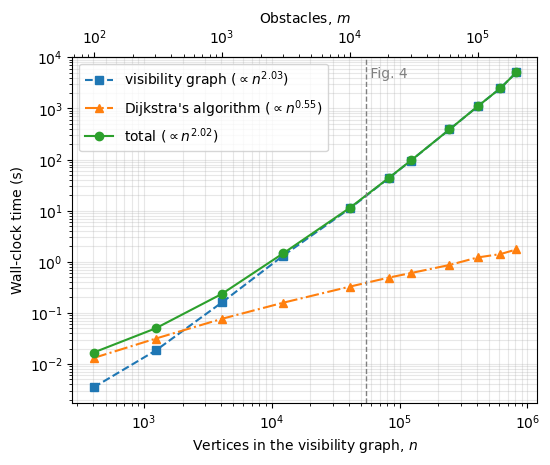

In [ ]:
paper = pd.read_csv("data/fig3_scaling_results.csv")
paper = paper.rename(columns={
    "requested_obstacles": "obstacles",
    "n_vertices": "vertices",
    "t_construct_wall": "visibility",
    "t_search_wall": "dijkstra",
    "t_algorithm_wall": "total",
})

print(f"{len(paper)} trials, recorded on {paper['platform'][0]} with {paper['numba_threads'][0]} Numba threads")
plot_scaling(paper)

## Rerun the benchmark (optional)

Set `RUN_BENCHMARK = True` to run it. The default `SIZES` finishes in a few minutes. The paper's full sweep (up to 200,000 obstacles) takes several hours; uncomment `FULL_SIZES` to run it. Results are appended to `fig3_results.csv` after every trial, so an interrupted run picks up where it left off.

Absolute times depend on your CPU. On small sweeps, fixed overhead also pulls the slopes below the paper's values.

In [ ]:
from vine_planner.obstacle_course import ObstacleCourse
from vine_planner.path_planner import PathPlanner
from vine_planner.utils import suggested_radius

RUN_BENCHMARK = False                                                # set to True to time your machine

SIZES = [(100, 3), (300, 3), (1_000, 3), (3_000, 2), (10_000, 1)]   # (obstacles, repetitions)
# FULL_SIZES = [(100, 30), (300, 30), (1_000, 30), (3_000, 30), (10_000, 20), (20_000, 12),
#               (30_000, 10), (60_000, 5), (100_000, 3), (150_000, 2), (200_000, 1)]
# SIZES = FULL_SIZES

WIDTH = HEIGHT = 8.0
MIN_VERTICES, MAX_VERTICES = 3, 6
RESULTS = Path("fig3_results.csv")


def course_size(num_obstacles):
    """Inner radius and annulus fraction that keep density fixed.

    The radius shrinks as obstacles are added so the covered area stays the same,
    and the annulus (spread in obstacle size) stays at 1% of the radius.
    """
    mean = suggested_radius(WIDTH, HEIGHT, num_obstacles, MIN_VERTICES, MAX_VERTICES, annulus_offset=0.0)
    annulus = 0.01 * mean
    radius = suggested_radius(WIDTH, HEIGHT, num_obstacles, MIN_VERTICES, MAX_VERTICES, annulus_offset=annulus)
    return radius, annulus / min(WIDTH, HEIGHT)


def run_trial(num_obstacles, rep):
    seed = int(np.random.SeedSequence([20260913, num_obstacles, rep]).generate_state(1)[0])
    radius, annulus_fraction = course_size(num_obstacles)
    course = ObstacleCourse.random(
        width=WIDTH, height=HEIGHT, num_obstacles=num_obstacles, seed=seed,
        radius=radius, annulus_fraction=annulus_fraction,
        min_vertices=MIN_VERTICES, max_vertices=MAX_VERTICES,
    )

    t0 = time.perf_counter()
    planner = PathPlanner(course, length_units="ft")    # builds the visibility graph
    t1 = time.perf_counter()
    planner.compute_pressure_path(verify=False)          # modified Dijkstra
    t2 = time.perf_counter()

    return {"obstacles": num_obstacles, "rep": rep, "vertices": planner.vertex_count,
            "visibility": t1 - t0, "dijkstra": t2 - t1, "total": t2 - t0}

In [ ]:
if not RUN_BENCHMARK:
    print("Benchmark skipped. Set RUN_BENCHMARK = True above to time the planner on your machine.")
else:
    run_trial(100, 999)   # warm-up so Numba's compile time isn't counted (not saved)

    done = pd.read_csv(RESULTS) if RESULTS.exists() else pd.DataFrame(columns=["obstacles", "rep"])
    if not {"obstacles", "rep"} <= set(done.columns):
        raise ValueError(f"{RESULTS} has unexpected columns; delete it or point RESULTS at a new file.")
    done_keys = set(zip(done["obstacles"], done["rep"]))

    for num_obstacles, reps in SIZES:
        for rep in range(reps):
            if (num_obstacles, rep) in done_keys:
                continue
            row = run_trial(num_obstacles, rep)
            pd.DataFrame([row]).to_csv(RESULTS, mode="a", header=not RESULTS.exists(), index=False)
            print(f"{num_obstacles:>7,} obstacles, rep {rep}: {row['total']:.3f} s")

    plot_scaling(pd.read_csv(RESULTS))